# Bài 1 - Phân lớp Iris bằng Decision Tree, Naive Bayes, KNN và Neural Network

**Sinh viên:** Nguyễn Đức Vinh  
**MSSV:** 6451071087

Xây dựng, đánh giá bốn mô hình phân lớp trên bộ dữ liệu Iris theo yêu cầu trang 1-4 của tài liệu LAB3.

> Chạy lần lượt các cell từ trên xuống dưới trong Google Colab. Mỗi notebook là một bài độc lập.

## 1. Khai báo thư viện và thông tin sinh viên

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix)

print("Nguyễn Đức Vinh - MSSV: 6451071087")
tf.keras.utils.set_random_seed(42)

Nguyễn Đức Vinh - MSSV: 6451071087


## 2. Đọc và khảo sát dữ liệu Iris (câu a, b)

In [7]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
iris = load_iris()
X_raw = iris.data.astype("float32")
y = iris.target
feature_names = iris.feature_names
class_names = iris.target_names

print("Tên thuộc tính:", feature_names)
print("Tên lớp:", class_names)
print("Số mẫu:", X_raw.shape[0])
print("Số thuộc tính:", X_raw.shape[1])
print("Kích thước target:", y.shape)

iris_df = pd.DataFrame(X_raw, columns=feature_names)
iris_df["class"] = [class_names[i] for i in y]
display(iris_df.head())
print("Thống kê mô tả:")
display(iris_df[feature_names].describe().T)

Nguyễn Đức Vinh - MSSV: 6451071087
Tên thuộc tính: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Tên lớp: ['setosa' 'versicolor' 'virginica']
Số mẫu: 150
Số thuộc tính: 4
Kích thước target: (150,)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),class
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Thống kê mô tả:


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765299,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


## 3. Chuẩn hóa và chia tập dữ liệu (câu c, d)

In [8]:
# Làm đúng hướng dẫn: chia từng cột cho giá trị lớn nhất của cột đó.
print("Nguyễn Đức Vinh - MSSV: 6451071087")
feature_max = X_raw.max(axis=0)
X = X_raw / feature_max

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("y_train:", y_train.shape, "y_test:", y_test.shape)

Nguyễn Đức Vinh - MSSV: 6451071087
X_train: (120, 4) X_test: (30, 4)
y_train: (120,) y_test: (30,)


## 4. Hàm đánh giá mô hình và các mô hình truyền thống (câu e, f, g)

Nguyễn Đức Vinh - MSSV: 6451071087

===== Decision Tree =====
Accuracy: 0.9333
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30



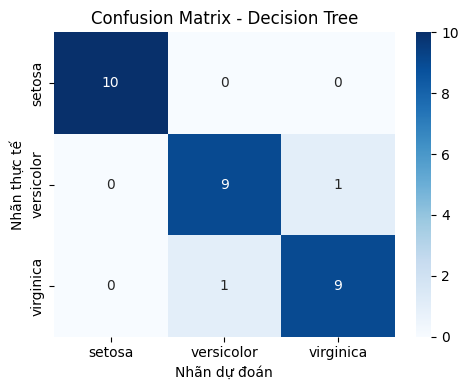


===== Gaussian Naive Bayes =====
Accuracy: 0.9667
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    0.9000    0.9474        10
   virginica     0.9091    1.0000    0.9524        10

    accuracy                         0.9667        30
   macro avg     0.9697    0.9667    0.9666        30
weighted avg     0.9697    0.9667    0.9666        30



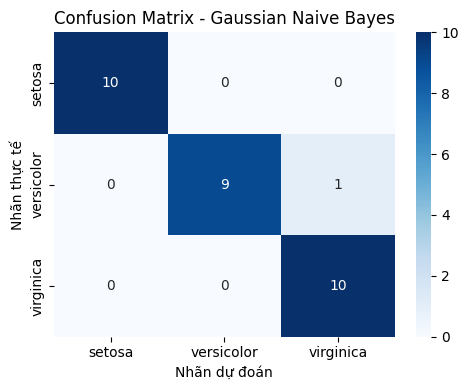


===== K Nearest Neighbors (k=5) =====
Accuracy: 0.9333
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30



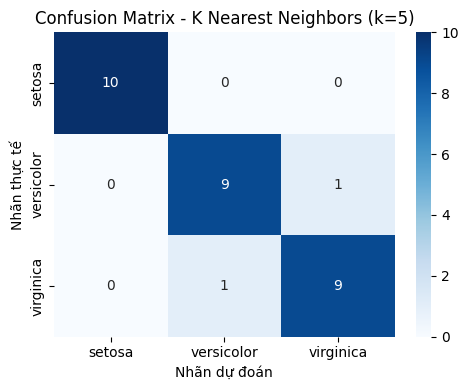

In [9]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
def evaluate_model(model, X_eval, y_true, model_name):
    y_pred = model.predict(X_eval)
    print(f"\n===== {model_name} =====")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print(classification_report(y_true, y_pred, target_names=class_names,
                                digits=4, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Nhãn dự đoán")
    plt.ylabel("Nhãn thực tế")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()
    return y_pred

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Gaussian Naive Bayes": GaussianNB(),
    "K Nearest Neighbors (k=5)": KNeighborsClassifier(n_neighbors=5)
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = evaluate_model(model, X_test, y_test, name)

## 5. Neural Network bằng Keras (câu h)

Nguyễn Đức Vinh - MSSV: 6451071087

===== Decision Tree =====
Accuracy: 0.9333
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30



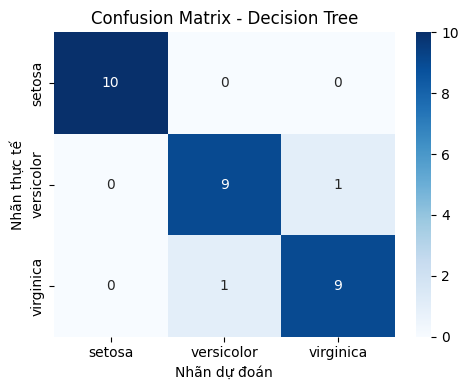


===== Gaussian Naive Bayes =====
Accuracy: 0.9667
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    0.9000    0.9474        10
   virginica     0.9091    1.0000    0.9524        10

    accuracy                         0.9667        30
   macro avg     0.9697    0.9667    0.9666        30
weighted avg     0.9697    0.9667    0.9666        30



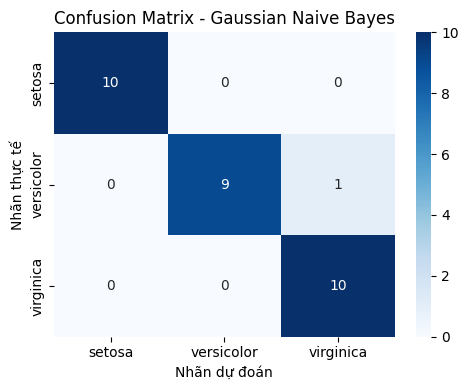


===== K Nearest Neighbors (k=5) =====
Accuracy: 0.9333
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30



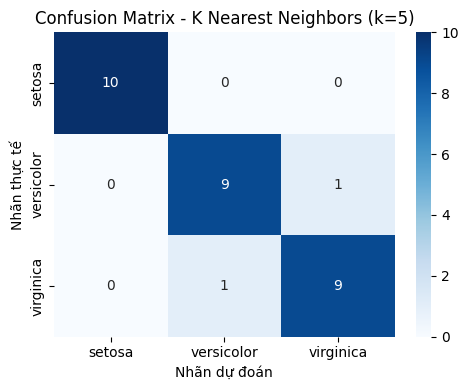

Epoch 1/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5167 - loss: 1.0702
Epoch 2/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7667 - loss: 0.9330
Epoch 3/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6917 - loss: 0.7794
Epoch 4/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7417 - loss: 0.6284
Epoch 5/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8083 - loss: 0.5205
Epoch 6/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8917 - loss: 0.4472
Epoch 7/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9417 - loss: 0.3921
Epoch 8/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9417 - loss: 0.3491
Epoch 9/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9500 - loss: 0.3121
Epoch 10/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9500 - loss: 0.2803
Epoch 11/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9583 - loss: 0.2525
Epoch 12/100
120/120 ━━━━━━━━━━━━━━━━━━━━

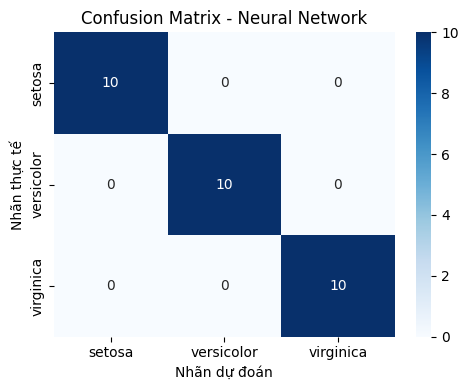

In [10]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
def evaluate_model(model, X_eval, y_true, model_name):
    y_pred = model.predict(X_eval)
    print(f"\n===== {model_name} =====")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print(classification_report(y_true, y_pred, target_names=class_names,
                                digits=4, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Nhãn dự đoán")
    plt.ylabel("Nhãn thực tế")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()
    return y_pred

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Gaussian Naive Bayes": GaussianNB(),
    "K Nearest Neighbors (k=5)": KNeighborsClassifier(n_neighbors=5)
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = evaluate_model(model, X_test, y_test, name)
nn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(10, activation="relu"),
    tf.keras.layers.Dense(20, activation="relu"),
    tf.keras.layers.Dense(len(class_names), activation="softmax")
])

nn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = nn_model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=1,
    verbose=1
)

nn_prob = nn_model.predict(X_test, verbose=0)
nn_pred = np.argmax(nn_prob, axis=1)
predictions["Neural Network"] = nn_pred
print("\n===== Neural Network =====")
print("Accuracy:", round(accuracy_score(y_test, nn_pred), 4))
print(classification_report(y_test, nn_pred, target_names=class_names,
                            digits=4, zero_division=0))
cm = confusion_matrix(y_test, nn_pred, labels=np.arange(len(class_names)))
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.title("Confusion Matrix - Neural Network")
plt.tight_layout()
plt.show()

## 6. Dự đoán ba mẫu dữ liệu mới (câu i)

In [6]:
new_samples = np.array([
    [6.2, 2.9, 4.3, 1.3],
    [5.1, 3.5, 1.4, 0.2],
    [7.3, 2.8, 6.4, 2.1]
], dtype="float32")
new_samples_scaled = new_samples / feature_max

all_models = {**models, "Neural Network": nn_model}
for name, model in all_models.items():
    pred = model.predict(new_samples_scaled, verbose=0) if name == "Neural Network" else model.predict(new_samples_scaled)
    if name == "Neural Network":
        pred = np.argmax(pred, axis=1)
    print(f"\n{name}:")
    for i, label in enumerate(pred, start=1):
        print(f"Mẫu {i}: {class_names[int(label)]}")


Decision Tree:
Mẫu 1: versicolor
Mẫu 2: setosa
Mẫu 3: virginica

Gaussian Naive Bayes:
Mẫu 1: versicolor
Mẫu 2: setosa
Mẫu 3: virginica

K Nearest Neighbors (k=5):
Mẫu 1: versicolor
Mẫu 2: setosa
Mẫu 3: virginica

Neural Network:
Mẫu 1: versicolor
Mẫu 2: setosa
Mẫu 3: virginica


## 7. Nhận xét, đánh giá (câu j)

Qua kết quả thực nghiệm, cả 4 mô hình đều phân loại tốt trên bộ dữ liệu Iris:
- Decision Tree: Accuracy đạt 93.33%.
- Naive Bayes: Accuracy đạt 96.67%.
- KNN: Accuracy đạt 93.33%.
- Neural Network: Accuracy đạt 100%, phân loại chính xác cả 3 lớp hoa.
Kết luận: Neural Network cho kết quả tốt nhất trong lần thực nghiệm này, tiếp theo là Naive Bayes. Decision Tree và KNN có hiệu suất tương đương. Tuy nhiên, do tập test chỉ có 30 mẫu nên cần thêm dữ liệu để đánh giá khả năng tổng quát của mô hình.